# AmineVQE: Quantum First Steps Toward Antidepressant Chemistry

In this project we use a chemistry-derived molecular Hamiltonian to demonstrate how a quantum circuit can approximate the electronic ground-state energy of a nitrogen-containing molecule.

**Project question:** Can a simple two-qubit variational quantum eigensolver (VQE) recover the ground-state energy of a reduced NH₃ electronic Hamiltonian?
**Extension question:** Can the same two-qubit circuit also find the vibrational ground state (zero-point energy) of NH₃'s N–H symmetric stretch?

**Description of our motivation:** Many antidepressants contain amine groups, and the electronic structure of their nitrogen atom shapes how these molecules become protonated and interact with their targets. Ammonia (NH₃) is the simplest nitrogen compound and the parent structure of all amines. It is not itself an organic amine or a drug, but its small size makes it an ideal system for learning a molecular VQE workflow. Once that workflow is working, we can extend it to methylamine and eventually to real drug fragments.

***Disclamer:** We do **not** predict drug efficacy, transporter binding, amine pKa, or the energy of any real bond in this project.*

**Methods:** PySCF, Qiskit Nature, two-qubit VQE, geometry optimization, harmonic frequencies, one-mode vibrational VQE

**Molecule:** Ammonia (NH₃)

**Model:** STO-3G, 2 active electrons in 2 spatial orbitals. We use the minimal STO-3G basis and focus the quantum calculation on the two most chemically relevant electrons, the nitrogen lone pair region, while treating the other eight electrons classically.



## In this project we did:

1. Built a real molecular model of ammonia (NH₃). We started from 3D atomic coordinates and used PySCF to compute the molecule’s electronic integrals in the minimal STO-3G basis (10 electrons, 8 spatial orbitals).
2. Reduced it to a small active space. We kept 2 electrons in 2 orbitals (the frontier orbitals, largely involving the nitrogen lone pair) and treated the other 8 electrons classically as a constant energy offset.
3. Mapped the chemistry onto qubits. Using Qiskit Nature’s parity mapping with known particle counts, we turned the problem into a 2-qubit Hamiltonian with 9 Pauli terms.
4. Computed an exact benchmark. We diagonalized the 4 × 4 Hamiltonian matrix directly to get the true ground-state energy of this reduced model.
5. Designed a simple quantum circuit (ansatz). It has 3 parameters (two RY rotations and one controlled-RY) and can represent any real two-qubit state, so it can reach the exact answer.
6. Ran the VQE. The COBYLA optimizer tuned the circuit angles to minimize energy, with 3 random starting points for robustness.
7. Reached high accuracy. The best VQE run matched the exact energy to within about 0.008 mHa, far below our 1 mHa target.
8. Validated the results. We checked that the Hamiltonian is Hermitian, that the circuit energy matches direct matrix calculation, and that VQE never went below the exact ground state (the variational principle).
9. Visualized the results. We made a convergence plot and a per-seed error chart.
10. Extended the method to molecular vibrations. We optimized the NH₃ geometry, computed its 6 vibrational modes, scanned the energy along the N–H symmetric stretch, built a 4-level vibrational Hamiltonian on 2 qubits, and found its ground state (the zero-point energy) with the same 3-parameter circuit.
11. Set out next steps. The pipeline could potentially be extended to methylamine, then to protonation studies and antidepressant fragments.


### Project workflow

**Electronic VQE (Sections 1–8)**
NH₃ coordinates → molecular integrals (PySCF) → active-space Hamiltonian, 2 electrons in 2 orbitals (Qiskit Nature) → parity mapping to a 2-qubit Pauli Hamiltonian → VQE (3-parameter circuit + COBYLA) → exact diagonalization → convergence and error graphs.

**Vibrational VQE (Section 9)**
NH₃ coordinates → geometry optimization (PySCF) → Hessian and 6 normal modes → energy scan along the N–H symmetric stretch → anharmonic potential fit → 4-level vibrational Hamiltonian → binary mapping to 2 qubits → VQE (same circuit + COBYLA) → exact diagonalization → potential, convergence, and animation graphs.

**Shared core:** both parts turn a piece of NH₃ physics into a 2-qubit Hamiltonian and solve it with the same circuit and optimizer, checked against an exact answer.




- `pyscf` computes the molecular integrals using classical quantum chemistry.
- `qiskit-nature` creates and reduces the fermionic Hamiltonian, then maps it to qubits.
- `qiskit` simulates the quantum circuit.
- `scipy` optimizes the circuit parameters.

In [1]:
%pip install -q "qiskit>=2.0,<3" "qiskit-nature>=0.8,<0.9" "pyscf>=2.5,<3" scipy numpy matplotlib pyberny

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer
from qiskit_nature.second_q.mappers import ParityMapper

np.set_printoptions(precision=6, suppress=True)


## 1. Model of ammonia (NH₃)

In [3]:
# Coordinates are in angstroms (A), close to an idealized pyramidal NH3.
# We keep all atom positions fixed in the electronic part (Sections 1-8).
# Section 9 (vibrational extension) starts from these coordinates and optimizes them.
NH3_GEOMETRY = """
N   0.0000   0.0000   0.0000
H   0.0000   0.0000   1.0100
H   0.9530   0.0000  -0.3370
H  -0.4765   0.8253  -0.3370
"""

# PySCF calculates one- and two-electron integrals for the molecule.
driver = PySCFDriver(
    atom=";".join(line.strip() for line in NH3_GEOMETRY.strip().splitlines()),
    basis="sto3g",
    unit=DistanceUnit.ANGSTROM,
    charge=0,
    spin=0,     # 2S = 0: a closed-shell, singlet reference
)
full_problem = driver.run()

print("NH3 (full problem):")
print("  Electrons (alpha, beta):", full_problem.num_particles)
print("  Spatial orbitals:", full_problem.num_spatial_orbitals)
print("  Hartree-Fock reference total energy (Ha):", round(float(full_problem.reference_energy), 8))

NH3 (full problem):
  Electrons (alpha, beta): (5, 5)
  Spatial orbitals: 8
  Hartree-Fock reference total energy (Ha): -55.45258128




The nonrelativistic electronic Hamiltonian contains **electron kinetic energy, electron–nucleus attraction, and electron–electron repulsion**. Its coefficients depend on the molecule's nuclear coordinates and orbital basis.

The coefficients below come from PySCF's calculation of molecular integrals.

### Our molecular assumptions

- **Molecule:** neutral NH₃ with 10 electrons, at a fixed approximate pyramidal geometry. *This applies to Sections 1–8, the vibrational extension in Section 9 uses the optimized geometry.*
- **Basis:** STO-3G (smallest basis, not chemically high accuracy).
- **Approximation:** nuclei are stationary (Born–Oppenheimer approximation), nonrelativistic electronic structure.
- **Method used to construct orbitals:** restricted Hartree–Fock in PySCF.


## 2. Reduce to a small active space

Full NH₃ has 10 electrons. We focus on **2 active electrons in 2 spatial orbitals**, while Qiskit Nature incorporates the effect of the remaining inactive electrons into an effective Hamiltonian and a constant energy shift.

We choose the default active orbitals near the occupied–unoccupied frontier; we are **not claiming** this tiny space is sufficient for accurate NH₃ chemistry or N–H bond dissociation.

## 3. Mapping the chemistry into qubits
Two spatial orbitals correspond to four spin orbitals. We use a parity mapping **with the known active particle counts** (1 alpha, 1 beta), which uses the relevant symmetry sector and reduces four spin-orbital qubits to **two mapped qubits**.

In [4]:
# Active-space transformation: 2 electrons, 2 spatial orbitals.
reduced_problem = ActiveSpaceTransformer(
    num_electrons=2,
    num_spatial_orbitals=2,
).transform(full_problem)

# Parity mapping with particle counts selects the appropriate parity sector.
mapper = ParityMapper(num_particles=reduced_problem.num_particles)
fermionic_hamiltonian = reduced_problem.hamiltonian.second_q_op()
H_qubit = mapper.map(fermionic_hamiltonian).simplify()

print("Active particles (alpha, beta):", reduced_problem.num_particles)
print("Active spatial orbitals:", reduced_problem.num_spatial_orbitals)
print("Mapped qubits:", H_qubit.num_qubits)
print("Nonzero Pauli terms:", len(H_qubit))

assert reduced_problem.num_particles == (1, 1), "Expected 1 alpha and 1 beta active electron."
assert H_qubit.num_qubits == 2, "Expected the 2-qubit parity-reduced Hamiltonian."

print("\nQubit Hamiltonian (coefficients in Hartree):")
for pauli, coefficient in zip(H_qubit.paulis.to_labels(), H_qubit.coeffs):
    print(f"  {float(coefficient.real):+.8f} × {pauli}")

Active particles (alpha, beta): (1, 1)
Active spatial orbitals: 2
Mapped qubits: 2
Nonzero Pauli terms: 9

Qubit Hamiltonian (coefficients in Hartree):
  -0.86353737 × II
  +0.33352756 × IZ
  +0.00654517 × IX
  -0.33352756 × ZI
  +0.00654517 × XI
  -0.07442662 × ZZ
  +0.00654529 × XZ
  -0.00654529 × ZX
  +0.03764759 × XX



## 4. Ground-state energy of this reduced model

With 2 qubits, the Hamiltonian is a **4 × 4 matrix**. We can diagonalize it on an ordinary computer. This gives a trustworthy benchmark **for this same active-space Hamiltonian and parity sector**.

The mapped `second_q_op()` omits certain constant contributions that are not measured on the circuit: notably nuclear repulsion and the frozen/inactive electron contribution. We add all Qiskit Nature Hamiltonian constants to both exact and VQE energies to obtain comparable **total energies within our approximate model**.

We are distinguishing:

- **Mapped energy:** eigenvalue/expectation of `H_qubit`.
- **Approximate molecular total energy:** mapped energy + stored constant offsets.

*Exact* below means exact diagonalization *within the specified reduced model*, not the exact real-world energy of NH₃.

In [5]:
# Convert the two-qubit Hamiltonian to a dense 4×4 matrix.
H_matrix = H_qubit.to_matrix()

# Sanity checks: a valid energy Hamiltonian is Hermitian.
assert np.allclose(H_matrix, H_matrix.conj().T, atol=1e-10)
assert np.max(np.abs(H_matrix.imag)) < 1e-9, "Expected a real-valued matrix for this model."

# Ground-state electronic energy of the mapped active-space operator.
eigenvalues, eigenvectors = np.linalg.eigh(H_matrix)
E_exact_mapped = float(eigenvalues[0].real)

# Constants that Qiskit Nature does NOT include in the qubit operator.
constant_terms = {
    name: float(np.real(value))
    for name, value in reduced_problem.hamiltonian.constants.items()
}
E_offset = sum(constant_terms.values())
E_exact_total = E_exact_mapped + E_offset

print("Stored constant offsets (Hartree):")
for name, value in constant_terms.items():
    print(f"  {name}: {value:+.8f}")
print(f"  Total offset: {E_offset:+.8f} Ha")
print(f"\nExact mapped energy: {E_exact_mapped:.8f} Ha")
print(f"Exact model total energy: {E_exact_total:.8f} Ha")

Stored constant offsets (Hartree):
  nuclear_repulsion_energy: +11.95874034
  ActiveSpaceTransformer: -65.95515575
  Total offset: -53.99641541 Ha

Exact mapped energy: -1.45722789 Ha
Exact model total energy: -55.45364331 Ha


## 5. Build the variational quantum circuit (ansatz)

VQE minimizes the energy expectation value

$$E(\boldsymbol{\theta})=\langle\psi(\boldsymbol{\theta})|H|\psi(\boldsymbol{\theta})\rangle.$$

Our **two-qubit ansatz** has only **three parameters** and uses two `RY` rotations and one controlled `RY` rotation (`CRY`). Starting from $|00\rangle$, it can represent any real, normalized two-qubit pure state, up to a global phase. That makes it expressive enough to represent an exact eigenstate of the real 4 × 4 Hamiltonian, given successful optimization.

In [6]:
# A compact, expressive, 3-parameter two-qubit circuit.
def make_ansatz(theta):
    """Create a two-qubit trial state from three rotation angles (radians)."""
    a, b, c = [float(value) for value in theta]
    circuit = QuantumCircuit(2)
    circuit.ry(a, 0)
    circuit.ry(b, 1)
    circuit.cry(c, 0, 1)
    return circuit

# Display the quantum gates as text
print(make_ansatz([0.2, 0.3, -0.4]).draw(output="text"))

def mapped_energy(theta):
    """Exact statevector estimate of <psi(theta)|H_qubit|psi(theta)> in Hartree."""
    state = Statevector(make_ansatz(theta))
    return float(np.real(state.expectation_value(H_qubit)))

# Cross-check Qiskit expectation against direct NumPy matrix multiplication.
test_angles = np.array([0.2, 0.3, -0.4])
state = Statevector(make_ansatz(test_angles)).data
matrix_energy = float(np.real(np.vdot(state, H_matrix @ state)))
assert np.isclose(mapped_energy(test_angles), matrix_energy, atol=1e-10)
print("Circuit energy check passed:", round(matrix_energy, 8), "Ha")

     ┌─────────┐            
q_0: ┤ Ry(0.2) ├─────■──────
     ├─────────┤┌────┴─────┐
q_1: ┤ Ry(0.3) ├┤ Ry(-0.4) ├
     └─────────┘└──────────┘
Circuit energy check passed: -0.9205196 Ha


## 6. VQE with COBYLA

The optimizer changes the circuit's three angles to minimize its energy. We use **COBYLA**, a gradient-free method. To reduce the chance of a poor local optimum, we try three reproducible random initializations and select the lowest-energy result.

For this very small problem, VQE calls a noiseless **statevector simulator**. No shots or real hardware noise are included. That isolates the core variational algorithm and makes the project reproducible.

In [7]:
# A small number of reproducible restarts makes optimization more robust.
SEEDS = [7, 21, 42]
MAX_EVAL = 100
runs = []

for seed in SEEDS:
    rng = np.random.default_rng(seed)
    initial_angles = rng.uniform(-np.pi, np.pi, size=3)
    history = []

    def objective(theta):
        energy = mapped_energy(theta)
        history.append(energy)
        return energy

    result = minimize(
        objective,
        x0=initial_angles,
        method="COBYLA",
        options={"maxiter": MAX_EVAL, "rhobeg": 0.6, "tol": 1e-9},
    )
    runs.append({"seed": seed, "result": result, "history": np.array(history)})
    print(f"Seed {seed:>2}: mapped E={result.fun:.9f} Ha; "
          f"error={max(result.fun - E_exact_mapped, 0)*1000:.4f} mHa; "
          f"evaluations={len(history)}")

# Choose the best of the three optimization runs.
best_run = min(runs, key=lambda item: item["result"].fun)
best_result = best_run["result"]
E_vqe_mapped = mapped_energy(best_result.x)
E_vqe_total = E_vqe_mapped + E_offset
error_ha = E_vqe_mapped - E_exact_mapped
error_mha = 1000 * error_ha

print("\nBest starting seed:", best_run["seed"])
print("Best circuit parameters (radians):", np.round(best_result.x, 5))
print(f"VQE mapped energy:      {E_vqe_mapped:.10f} Ha")
print(f"Exact mapped energy:    {E_exact_mapped:.10f} Ha")
print(f"VQE total model energy: {E_vqe_total:.10f} Ha")
print(f"Exact total model E:    {E_exact_total:.10f} Ha")
print(f"Algorithmic error:      {error_ha:.8e} Ha ({error_mha:.5f} mHa)")

Seed  7: mapped E=-1.457219413 Ha; error=0.0085 mHa; evaluations=100
Seed 21: mapped E=-1.456320113 Ha; error=0.9078 mHa; evaluations=100
Seed 42: mapped E=-1.456633244 Ha; error=0.5946 mHa; evaluations=100

Best starting seed: 7
Best circuit parameters (radians): [3.08483 3.47394 2.80974]
VQE mapped energy:      -1.4572194129 Ha
Exact mapped energy:    -1.4572278932 Ha
VQE total model energy: -55.4536348276 Ha
Exact total model E:    -55.4536433079 Ha
Algorithmic error:      8.48033886e-06 Ha (0.00848 mHa)


## 7. Visualize and validate the results

**Figure 1: VQE convergence.** Each curve tracks circuit energy evaluations during an optimizer run; the horizontal line is the exact result for the same reduced Hamiltonian.

**Figure 2: Error by starting seed.** The result measures optimization error (in milli-Hartree) within our reduced active-space model. It is **not** a measure of the physical accuracy of STO-3G or of our truncated model of NH₃.

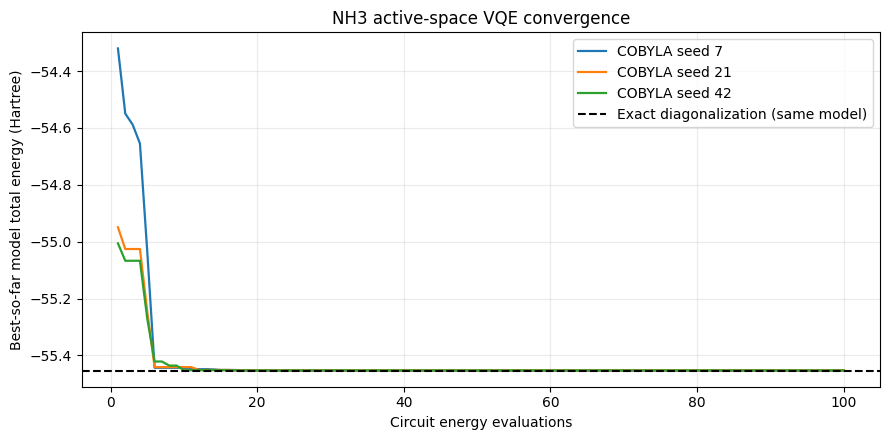

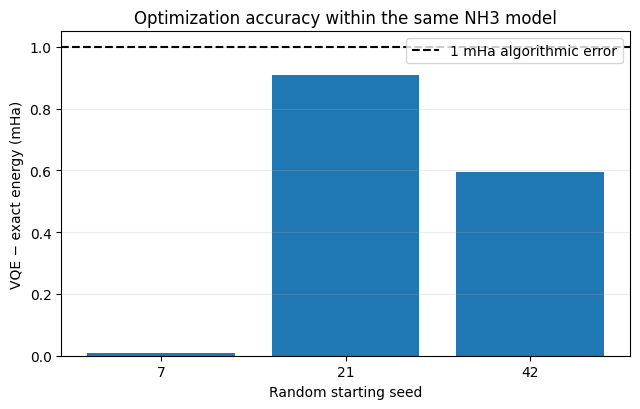

In [8]:
# Figure 1: convergence against the number of energy evaluations.
fig, ax = plt.subplots(figsize=(9, 4.5))
for run in runs:
    h = run["history"] + E_offset
    label = f"COBYLA seed {run['seed']}"
    ax.plot(np.arange(1, len(h) + 1), np.minimum.accumulate(h), label=label, lw=1.6)
ax.axhline(E_exact_total, color="black", ls="--", lw=1.5,
           label="Exact diagonalization (same model)")
ax.set_title("NH3 active-space VQE convergence")
ax.set_xlabel("Circuit energy evaluations")
ax.set_ylabel("Best-so-far model total energy (Hartree)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("nh3_vqe_convergence.png", dpi=170)
plt.show()

# Figure 2: optimization error for each initialization.
seed_errors_mha = [max(0, (run["result"].fun - E_exact_mapped) * 1000) for run in runs]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.bar([str(seed) for seed in SEEDS], seed_errors_mha)
ax.axhline(1.0, color="black", ls="--", label="1 mHa algorithmic error")
ax.set_xlabel("Random starting seed")
ax.set_ylabel("VQE − exact energy (mHa)")
ax.set_title("Optimization accuracy within the same NH3 model")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("nh3_vqe_optimization_error.png", dpi=170)
plt.show()

## 8. Validation

The **variational principle** means that, with exact noiseless expectation values, a trial circuit's energy cannot be lower than the ground-state energy of its Hamiltonian. We therefore check:

1. The mapped Hamiltonian is Hermitian.
2. The Qiskit statevector expectation agrees with direct matrix multiplication.
3. The best VQE energy is not below the exact eigenvalue (allowing tiny numerical rounding).
4. The VQE error is reported in **Hartree**, **milli-Hartree (mHa)**, and in the context of the chosen model.

We use **1 mHa** as a convenient algorithmic comparison target. Meeting it however does not imply that our approximate molecular model predicts experimentally accurate NH₃ energies.

In [9]:
assert np.isfinite(E_vqe_total)
assert E_vqe_mapped >= E_exact_mapped - 1e-7, "Variational bound unexpectedly violated."
assert np.isclose(E_vqe_total - E_exact_total, error_ha, atol=1e-9)

print("VALIDATION")
print("  Correct qubit count: PASS")
print("  Hermitian Hamiltonian: PASS")
print("  Circuit/matrix expectation agreement: PASS")
print("  Variational lower bound: PASS")
if error_ha <= 1e-3:
    print("  Under 1 mHa optimization error: PASS")
else:
    print("  Under 1 mHa optimization error: NOT YET")
    print("  Try increasing MAX_EVAL or adding another random seed.")
print("\nResult:")
print(f"  Molecule=NH3; active space=2e/2o; qubits={H_qubit.num_qubits}")
print(f"  Exact total model energy={E_exact_total:.8f} Ha")
print(f"  Best VQE total model energy={E_vqe_total:.8f} Ha")
print(f"  VQE error={error_mha:.6f} mHa")

VALIDATION
  Correct qubit count: PASS
  Hermitian Hamiltonian: PASS
  Circuit/matrix expectation agreement: PASS
  Variational lower bound: PASS
  Under 1 mHa optimization error: PASS

Result:
  Molecule=NH3; active space=2e/2o; qubits=2
  Exact total model energy=-55.45364331 Ha
  Best VQE total model energy=-55.45363483 Ha
  VQE error=0.008480 mHa




## 9. One-mode vibrational VQE (N–H symmetric stretch)

So far, the qubits described **electrons** at fixed nuclear positions. Molecules also **vibrate**: the nuclei oscillate around their equilibrium positions, and these vibrations are quantized too. Even in its lowest state a molecule keeps some vibrational energy, called the **zero-point energy (ZPE)**.

In this extension we reuse the *same* VQE idea and the *same* 3-parameter circuit for a vibrational problem.

**Why the N–H symmetric stretch?** All three N–H bonds lengthen and shorten together. It is a single, non-degenerate mode with a simple single-well potential, so it is a clean first vibrational test. N–H stretches are also the characteristic infrared signature of amines.





### 9.1 Optimize the geometry and compute the vibrational modes

Vibrations are defined around an **energy minimum**, so we first let PySCF optimize the NH₃ geometry (same STO-3G model as before). Then PySCF computes the **Hessian**, the matrix of second derivatives of the energy with respect to atomic positions. Diagonalizing the mass-weighted Hessian gives the **normal modes** (the independent ways the molecule vibrates) and their **harmonic frequencies**.

NH₃ has 4 atoms, so it has 3 × 4 − 6 = **6 vibrational modes**: the umbrella (symmetric bend), two degenerate asymmetric bends, the symmetric N–H stretch, and two degenerate asymmetric N–H stretches. We pick the symmetric stretch automatically: it is the mode in which all three N–H bonds stretch equally and strongly.


In [10]:
# Optimize the NH3 geometry and compute its harmonic vibrational modes.
from pyscf import gto, scf
from pyscf.data import nist
from pyscf.geomopt.berny_solver import optimize
from pyscf.hessian import thermo
from qiskit.quantum_info import SparsePauliOp, Operator

HA_TO_CM = nist.HARTREE2WAVENUMBER   # 1 Hartree = 219474.63 cm^-1
BOHR_TO_ANG = nist.BOHR              # 1 Bohr = 0.529177 Angstrom

# Same molecule, basis and method (RHF/STO-3G) as Sections 1-8, starting from the same coordinates.
mol_start = gto.M(
    atom=";".join(line.strip() for line in NH3_GEOMETRY.strip().splitlines()),
    basis="sto3g", charge=0, spin=0, unit="Angstrom", verbose=0,
)
mf_start = scf.RHF(mol_start).run()

# Vibrations are defined around an energy minimum, so optimize the geometry first.
mol_eq = optimize(mf_start, maxsteps=50)
mf_eq = scf.RHF(mol_eq).run()
E_eq = mf_eq.e_tot

# Hessian -> harmonic frequencies (cm^-1) and normal-mode displacement vectors.
hessian = mf_eq.Hessian().kernel()
harmonic = thermo.harmonic_analysis(mol_eq, hessian)
freqs_cm = np.asarray(harmonic["freq_wavenumber"])
assert not np.iscomplexobj(freqs_cm) and np.all(freqs_cm > 0), "Imaginary frequency: not a true minimum."

coords_eq = mol_eq.atom_coords()     # Bohr; atom 0 is N, atoms 1-3 are H

def nh_bond_lengths(coords):
    # The three N-H distances (same units as coords).
    return np.array([np.linalg.norm(coords[i] - coords[0]) for i in (1, 2, 3)])

r_eq = nh_bond_lengths(coords_eq)

# How much does each N-H bond change when we move a small step along each mode?
step = 0.01
bond_response = np.array([(nh_bond_lengths(coords_eq + step * m) - r_eq) / step
                          for m in harmonic["norm_mode"]])

# Symmetric stretch: all three bonds change by the same amount, and strongly.
is_symmetric = np.ptp(bond_response, axis=1) < 0.05 * np.abs(bond_response).max(axis=1)
k_stretch = int(np.argmax(np.where(is_symmetric, np.abs(bond_response.mean(axis=1)), 0.0)))
mode_vec = harmonic["norm_mode"][k_stretch]
if bond_response[k_stretch].mean() < 0:
    mode_vec = -mode_vec             # convention: positive displacement = longer N-H bonds
    bond_response[k_stretch] *= -1
omega_cm = float(freqs_cm[k_stretch])
omega_au = omega_cm / HA_TO_CM       # harmonic frequency in Hartree (hbar = 1)

print(f"Fixed starting geometry energy (Sections 1-8): {mf_start.e_tot:.8f} Ha")
print(f"Optimized geometry energy:                     {E_eq:.8f} Ha")
print(f"  Lowered by {1000 * (mf_start.e_tot - E_eq):.3f} mHa; optimized N-H length = {r_eq[0] * BOHR_TO_ANG:.4f} A\n")
print(f"{'Mode':>4} {'Harmonic freq (cm^-1)':>22}   N-H bond changes (relative)")
for k, (f, d) in enumerate(zip(freqs_cm, bond_response)):
    tag = "  <- symmetric N-H stretch (selected)" if k == k_stretch else ""
    print(f"{k:>4} {f:>22.1f}   {np.round(d, 3)}{tag}")


INFO:pyscf.geomopt.berny_solver.140242495946288:0 Internal coordinates:
INFO:pyscf.geomopt.berny_solver.140242495946288:0 * Number of fragments: 1
INFO:pyscf.geomopt.berny_solver.140242495946288:0 * Number of internal coordinates: 6
INFO:pyscf.geomopt.berny_solver.140242495946288:0 * Number of strong bonds: 3
INFO:pyscf.geomopt.berny_solver.140242495946288:0 * Number of strong angles: 3
INFO:pyscf.geomopt.berny_solver.140242495946288:1 Energy: -55.4525812763
INFO:pyscf.geomopt.berny_solver.140242495946288:1 Pure RFO step was performed:
INFO:pyscf.geomopt.berny_solver.140242495946288:1 * Trust radius: 0.3
INFO:pyscf.geomopt.berny_solver.140242495946288:1 * Number of negative eigenvalues: 0
INFO:pyscf.geomopt.berny_solver.140242495946288:1 * Lowest eigenvalue: 0.185
INFO:pyscf.geomopt.berny_solver.140242495946288:1 * lambda: -0.00414
INFO:pyscf.geomopt.berny_solver.140242495946288:1 Quadratic step: RMS: 0.0536, max: 0.0695
INFO:pyscf.geomopt.berny_solver.140242495946288:1 * Predicted ene

Fixed starting geometry energy (Sections 1-8): -55.45258128 Ha
Optimized geometry energy:                     -55.45541972 Ha
  Lowered by 2.838 mHa; optimized N-H length = 1.0326 A

Mode  Harmonic freq (cm^-1)   N-H bond changes (relative)
   0                 1411.3   [-0.059 -0.059 -0.059]
   1                 2076.1   [ 0.002 -0.008  0.009]
   2                 2076.1   [-0.01   0.006  0.006]
   3                 3831.8   [0.583 0.582 0.582]  <- symmetric N-H stretch (selected)
   4                 4106.7   [-0.848  0.418  0.432]
   5                 4106.9   [-0.008  0.739 -0.731]




### 9.2 Scan the energy along the symmetric stretch

We move the atoms along the selected normal mode and compute the RHF energy at each displaced geometry (a **single-point** calculation: the atoms are not re-optimized). This gives the **potential energy curve** $V(\xi)$ of the mode.

We use the **dimensionless normal coordinate** $\xi$: $\xi = 0$ is the equilibrium geometry, and in a perfectly harmonic potential $V(\xi) = \tfrac{1}{2}\hbar\omega\,\xi^2$. We scan $\xi$ from −3.5 to +3.5, which covers the classical turning points of the n = 3 level ($\xi = \pm\sqrt{7} \approx \pm 2.65$).

A real bond is **anharmonic**: compressing it costs more energy than stretching it by the same amount. We capture this by fitting a 6th-order polynomial. **Check:** the curvature of the fit at $\xi = 0$ must reproduce the harmonic frequency from the Hessian, an independent test of the scan.


In [11]:
#  Scan the RHF energy along the symmetric-stretch normal mode.
def geometry_at(xi):
    # Cartesian coordinates (Bohr) displaced by the dimensionless normal coordinate xi.
    # xi = sqrt(omega) * q in atomic units, and PySCF's normal modes use mass in amu,
    # so the mass-weighted displacement is Q = xi / sqrt(omega_au * amu_in_electron_masses).
    Q = xi / np.sqrt(omega_au * nist.AMU2AU)
    return coords_eq + Q * mode_vec

xi_scan = np.linspace(-3.5, 3.5, 15)
E_scan = []
dm_guess = mf_eq.make_rdm1()
for xi in xi_scan:
    mol_xi = mol_eq.copy()
    mol_xi.set_geom_(geometry_at(xi), unit="Bohr")
    mf_xi = scf.RHF(mol_xi)
    mf_xi.conv_tol = 1e-11
    mf_xi.kernel(dm0=dm_guess)       # start from the equilibrium density for smooth convergence
    assert mf_xi.converged, f"SCF did not converge at xi = {xi}"
    E_scan.append(mf_xi.e_tot)

V_scan = np.array(E_scan) - E_eq     # potential relative to the minimum (Hartree)
r_scan = np.array([nh_bond_lengths(geometry_at(xi))[0] for xi in xi_scan]) * BOHR_TO_ANG

# 6th-order polynomial fit of V(xi).
POLY_DEGREE = 6
poly_coeffs = np.polyfit(xi_scan, V_scan, POLY_DEGREE)
fit_residual_cm = np.abs(V_scan - np.polyval(poly_coeffs, xi_scan)).max() * HA_TO_CM
assert poly_coeffs[0] > 0, "Fitted potential must rise at large |xi|."

# Curvature check: V = 1/2 omega xi^2 near the minimum, so omega_fit = 2 * (xi^2 coefficient).
omega_fit_cm = 2 * poly_coeffs[-3] * HA_TO_CM

print(f"Scanned N-H bond lengths: {r_scan.min():.3f} to {r_scan.max():.3f} A (equilibrium {r_eq[0] * BOHR_TO_ANG:.3f} A)")
print(f"{'xi':>6} {'N-H (A)':>8} {'V (cm^-1)':>11}")
for xi, r, v in zip(xi_scan, r_scan, V_scan * HA_TO_CM):
    print(f"{xi:>6.2f} {r:>8.4f} {v:>11.1f}")
print(f"\nLargest fit residual: {fit_residual_cm:.2f} cm^-1")
print(f"Frequency from fit curvature: {omega_fit_cm:.1f} cm^-1 vs Hessian: {omega_cm:.1f} cm^-1")


Scanned N-H bond lengths: 0.841 to 1.224 A (equilibrium 1.033 A)
    xi  N-H (A)   V (cm^-1)
 -3.50   0.8413     34250.8
 -3.00   0.8686     23719.3
 -2.50   0.8960     15552.7
 -2.00   0.9233      9412.8
 -1.50   0.9506      5013.4
 -1.00   0.9780      2111.3
 -0.50   1.0053       499.4
  0.00   1.0326         0.0
  0.50   1.0600       460.3
  1.00   1.0873      1747.9
  1.50   1.1147      3747.9
  2.00   1.1420      6360.0
  2.50   1.1693      9496.1
  3.00   1.1967     13079.2
  3.50   1.2240     17041.4

Largest fit residual: 0.42 cm^-1
Frequency from fit curvature: 3831.9 cm^-1 vs Hessian: 3831.8 cm^-1



### 9.3 Build the 4-level vibrational Hamiltonian and map it to 2 qubits

The vibrational Hamiltonian of the mode is kinetic plus potential energy:

$$H_{\text{vib}} = -\frac{\hbar\omega}{2}\frac{d^2}{d\xi^2} + V(\xi).$$

We write it in the basis of **harmonic-oscillator states** $|n\rangle$ and keep only the **4 lowest levels** (n = 0, 1, 2, 3). This gives a real 4 × 4 matrix. In a perfectly harmonic potential it would be diagonal with energies $(n + \tfrac{1}{2})\hbar\omega$; anharmonicity adds off-diagonal couplings that mix the levels.

**Mapping to qubits:** 4 levels fit on 2 qubits with a **binary encoding**: $|n=0\rangle \to |00\rangle$, $|1\rangle \to |01\rangle$, $|2\rangle \to |10\rangle$, $|3\rangle \to |11\rangle$. Qiskit converts the 4 × 4 matrix into a sum of Pauli terms, just like the electronic Hamiltonian.

**Two references:**
- **Exact (4-level):** diagonalize the same 4 × 4 matrix. This is the benchmark for VQE.
- **Converged (60-level):** a much larger basis, computed classically. It shows how much the 4-level truncation itself costs.


In [12]:
# Vibrational Hamiltonian in the harmonic-oscillator basis, mapped to 2 qubits.
N_LEVELS = 4    # n = 0, 1, 2, 3  ->  2 qubits
N_BIG = 60      # large basis, used only for the converged classical reference

def vibrational_hamiltonian(n_basis):
    # H = (omega/2) p^2 + V(xi), with xi and p written using ladder operators (Hartree).
    a = np.diag(np.sqrt(np.arange(1, n_basis)), k=1)   # lowering operator
    X = (a + a.T) / np.sqrt(2)                          # position xi
    P2 = -((a.T - a) @ (a.T - a)) / 2                   # momentum squared
    V = sum(c * np.linalg.matrix_power(X, p) for p, c in enumerate(poly_coeffs[::-1]))
    return 0.5 * omega_au * P2 + V

H_big = vibrational_hamiltonian(N_BIG)
# Taking the 4 x 4 corner of the large-basis matrix gives exact matrix elements of the
# polynomial potential between the 4 lowest harmonic-oscillator states.
H_vib_matrix = H_big[:N_LEVELS, :N_LEVELS]
assert np.allclose(H_vib_matrix, H_vib_matrix.T), "Vibrational Hamiltonian must be symmetric."

# Binary encoding: level n -> 2-qubit basis state |n>.
H_vib = SparsePauliOp.from_operator(Operator(H_vib_matrix)).simplify()
assert H_vib.num_qubits == 2

E_vib_exact = np.linalg.eigvalsh(H_vib_matrix)           # same 4-level model as VQE
E_vib_converged = np.linalg.eigvalsh(H_big)[:N_LEVELS]   # truncation check
E_vib_harmonic = (np.arange(N_LEVELS) + 0.5) * omega_au  # simple harmonic model

print("4 x 4 vibrational Hamiltonian (cm^-1):")
print(np.round(H_vib_matrix * HA_TO_CM, 1))
print(f"\nQubit Hamiltonian: {len(H_vib)} Pauli terms (coefficients in cm^-1)")
for pauli, coefficient in zip(H_vib.paulis.to_labels(), H_vib.coeffs):
    print(f"  {coefficient.real * HA_TO_CM:+10.2f} x {pauli}")
print(f"\n{'n':>2} {'Harmonic':>10} {'Exact 4-level':>14} {'Converged':>10}   (cm^-1)")
for n in range(N_LEVELS):
    print(f"{n:>2} {E_vib_harmonic[n] * HA_TO_CM:>10.1f} {E_vib_exact[n] * HA_TO_CM:>14.1f} "
          f"{E_vib_converged[n] * HA_TO_CM:>10.1f}")
print(f"\nFundamental transition (n=0 -> 1), converged: "
      f"{(E_vib_converged[1] - E_vib_converged[0]) * HA_TO_CM:.1f} cm^-1 (harmonic: {omega_cm:.1f})")


4 x 4 vibrational Hamiltonian (cm^-1):
[[ 1926.3  -197.3    29.5  -167.7]
 [ -197.3  5799.8  -569.6    85.8]
 [   29.5  -569.6  9715.8 -1059.9]
 [ -167.7    85.8 -1059.9 13675.4]]

Qubit Hamiltonian: 10 Pauli terms (coefficients in cm^-1)
    +7779.32 x II
     -628.61 x IX
    -1958.28 x IZ
      +57.65 x XI
     -368.68 x XX
      -28.15 x XZ
     -200.94 x YY
    -3916.29 x ZI
     +431.28 x ZX
      +21.51 x ZZ

 n   Harmonic  Exact 4-level  Converged   (cm^-1)
 0     1915.9         1913.9     1913.9
 1     5747.7         5727.8     5718.1
 2     9579.5         9525.6     9493.3
 3    13411.3        13949.9    13239.5

Fundamental transition (n=0 -> 1), converged: 3804.1 cm^-1 (harmonic: 3831.8)




### 9.4 Run VQE on the vibrational Hamiltonian

We reuse **exactly the same 3-parameter circuit** (`make_ansatz`) and COBYLA optimizer from Sections 5–6. Only the Hamiltonian changes.

**Choosing the starting angles matters here.** The vibrational ground state is almost entirely $|n=0\rangle = |00\rangle$, with only small admixtures of higher levels caused by anharmonicity. When the first rotation angle is close to zero, the controlled-RY angle has almost no effect on the energy, so the energy landscape is very flat in that direction and COBYLA can stall. We therefore use a **warm start**: small random angles close to $|00\rangle$, the harmonic ground state. This is the vibrational equivalent of starting an electronic VQE from the Hartree–Fock state. For comparison, we also run **cold starts** from fully random angles, as in Section 6.

Energies are reported in **cm⁻¹**, the usual unit for vibrations (1 mHa ≈ 219 cm⁻¹). Our accuracy target is **1 cm⁻¹**.


In [13]:
#  VQE for the vibrational ground state, using the same circuit as before.
def vib_energy(theta):
    # Exact statevector estimate of <psi(theta)|H_vib|psi(theta)> in Hartree.
    return float(np.real(Statevector(make_ansatz(theta)).expectation_value(H_vib)))

# Cross-check Qiskit against direct matrix multiplication (as in Section 5).
psi_test = Statevector(make_ansatz(test_angles)).data
assert np.isclose(vib_energy(test_angles), np.real(np.vdot(psi_test, H_vib_matrix @ psi_test)), atol=1e-12)

MAX_EVAL_VIB = 300

def run_vib_vqe(x0, rhobeg):
    history = []
    def objective(theta):
        energy = vib_energy(theta)
        history.append(energy)
        return energy
    result = minimize(objective, x0=x0, method="COBYLA",
                      options={"maxiter": MAX_EVAL_VIB, "rhobeg": rhobeg, "tol": 1e-10})
    return result, np.array(history)

vib_runs = []
for start, low, high, rhobeg in [("warm", -1.0, 1.0, 0.3), ("cold", -np.pi, np.pi, 0.6)]:
    for seed in SEEDS:
        x0 = np.random.default_rng(seed).uniform(low, high, size=3)
        result, history = run_vib_vqe(x0, rhobeg)
        error_cm = (result.fun - E_vib_exact[0]) * HA_TO_CM
        vib_runs.append({"start": start, "seed": seed, "result": result, "history": history, "error_cm": error_cm})
        print(f"{start} start, seed {seed:>2}: E = {result.fun * HA_TO_CM:.4f} cm^-1; error = {error_cm:.4f} cm^-1")

best_vib = min((r for r in vib_runs if r["start"] == "warm"), key=lambda r: r["result"].fun)
E_vib_vqe = vib_energy(best_vib["result"].x)
vib_error_cm = (E_vib_vqe - E_vib_exact[0]) * HA_TO_CM

print(f"\nBest warm-start seed: {best_vib['seed']}")
print(f"VQE zero-point energy (this mode):  {E_vib_vqe * HA_TO_CM:.4f} cm^-1")
print(f"Exact 4-level zero-point energy:    {E_vib_exact[0] * HA_TO_CM:.4f} cm^-1")
print(f"VQE error:                          {vib_error_cm:.4f} cm^-1")
probs = np.abs(Statevector(make_ansatz(best_vib["result"].x)).data) ** 2
print("Level populations in the VQE state:", ", ".join(f"n={n}: {p:.4f}" for n, p in enumerate(probs)))


warm start, seed  7: E = 1913.9526 cm^-1; error = 0.0035 cm^-1
warm start, seed 21: E = 1913.9614 cm^-1; error = 0.0124 cm^-1
warm start, seed 42: E = 1913.9526 cm^-1; error = 0.0036 cm^-1
cold start, seed  7: E = 1924.8267 cm^-1; error = 10.8777 cm^-1
cold start, seed 21: E = 1913.9891 cm^-1; error = 0.0401 cm^-1
cold start, seed 42: E = 1913.9495 cm^-1; error = 0.0005 cm^-1

Best warm-start seed: 7
VQE zero-point energy (this mode):  1913.9526 cm^-1
Exact 4-level zero-point energy:    1913.9490 cm^-1
VQE error:                          0.0035 cm^-1
Level populations in the VQE state: n=0: 0.9973, n=1: 0.0025, n=2: 0.0000, n=3: 0.0002




### 9.5 Visualize the vibrational results

**Figure 3: Potential and vibrational levels.** The scanned RHF energies (points), the anharmonic fit (solid), and the harmonic approximation (dashed), plotted against the N–H bond length. Horizontal lines are the 4 levels of our 2-qubit model. The VQE ground state (zero-point level) is highlighted.

**Figure 4: VQE convergence.** The best-so-far error (log scale) for warm starts (solid) and cold starts (dashed). It shows why the starting point matters for this problem.


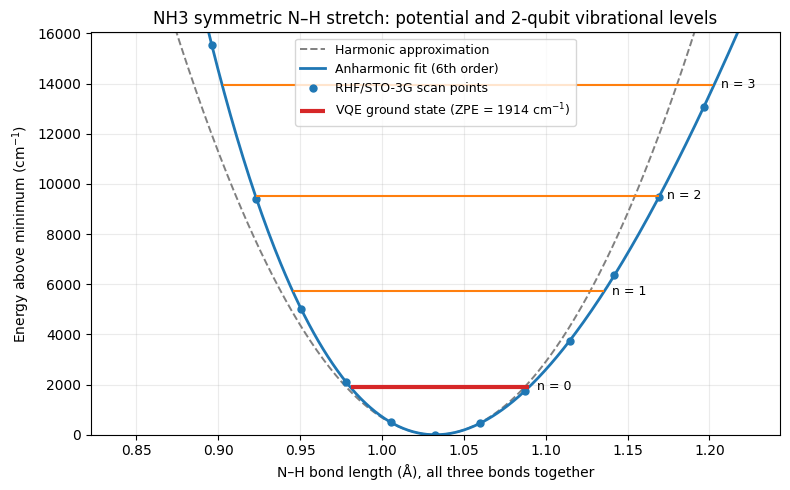

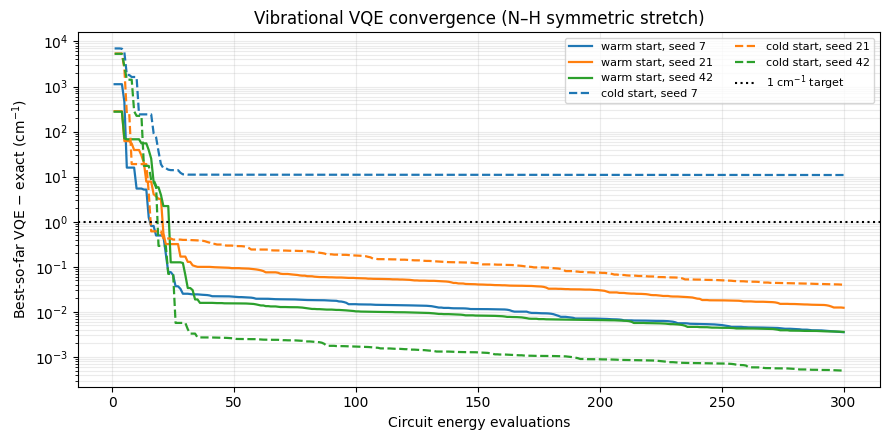

In [14]:
# Figure 3: potential energy curve with the vibrational levels of the 2-qubit model.
xi_dense = np.linspace(xi_scan.min(), xi_scan.max(), 400)
r_dense = np.array([nh_bond_lengths(geometry_at(x))[0] for x in xi_dense]) * BOHR_TO_ANG
V_fit_cm = np.polyval(poly_coeffs, xi_dense) * HA_TO_CM
V_harm_cm = 0.5 * omega_cm * xi_dense ** 2

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_dense, V_harm_cm, ls="--", color="gray", lw=1.4, label="Harmonic approximation")
ax.plot(r_dense, V_fit_cm, color="tab:blue", lw=2, label="Anharmonic fit (6th order)")
ax.plot(r_scan, V_scan * HA_TO_CM, "o", color="tab:blue", ms=5, label="RHF/STO-3G scan points")
for n, E_n in enumerate(E_vib_exact * HA_TO_CM):
    inside = V_fit_cm <= E_n                      # classically allowed region for this level
    ax.hlines(E_n, r_dense[inside].min(), r_dense[inside].max(), color="tab:orange", lw=1.5)
    ax.text(r_dense[inside].max() + 0.005, E_n, f"n = {n}", va="center", fontsize=9)
inside = V_fit_cm <= E_vib_vqe * HA_TO_CM
ax.hlines(E_vib_vqe * HA_TO_CM, r_dense[inside].min(), r_dense[inside].max(), color="tab:red", lw=3,
          label=f"VQE ground state (ZPE = {E_vib_vqe * HA_TO_CM:.0f} cm$^{{-1}}$)")
ax.set_ylim(0, 1.15 * E_vib_exact[-1] * HA_TO_CM)
ax.set_xlabel("N–H bond length (Å), all three bonds together")
ax.set_ylabel("Energy above minimum (cm$^{-1}$)")
ax.set_title("NH3 symmetric N–H stretch: potential and 2-qubit vibrational levels")
ax.grid(alpha=0.25)
ax.legend(loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig("nh3_vibrational_levels.png", dpi=170)
plt.show()

# [NEW] Figure 4: convergence of vibrational VQE, warm vs cold starts.
fig, ax = plt.subplots(figsize=(9, 4.5))
for run, color in zip(vib_runs, ["tab:blue", "tab:orange", "tab:green"] * 2):
    err = np.maximum((np.minimum.accumulate(run["history"]) - E_vib_exact[0]) * HA_TO_CM, 1e-6)
    ax.plot(np.arange(1, len(err) + 1), err, color=color, lw=1.6,
            ls="-" if run["start"] == "warm" else "--", label=f"{run['start']} start, seed {run['seed']}")
ax.axhline(1.0, color="black", ls=":", lw=1.5, label="1 cm$^{-1}$ target")
ax.set_yscale("log")
ax.set_xlabel("Circuit energy evaluations")
ax.set_ylabel("Best-so-far VQE − exact (cm$^{-1}$)")
ax.set_title("Vibrational VQE convergence (N–H symmetric stretch)")
ax.grid(alpha=0.25, which="both")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig("nh3_vibrational_vqe_convergence.png", dpi=170)
plt.show()




### 9.6 Validation of the vibrational extension

We check that:
1. The optimized geometry is a true minimum (no imaginary frequencies; checked in 9.1).
2. The curvature of the scanned potential reproduces the Hessian frequency (within 1%).
3. The vibrational Hamiltonian is symmetric (Hermitian) and the circuit energy matches direct matrix multiplication.
4. VQE never goes below the exact 4-level ground state (variational principle).
5. The best VQE run is within **1 cm⁻¹** of the exact 4-level ground state.
6. Truncating to 4 levels changes the ground-state energy by less than 1 cm⁻¹ compared with the converged 60-level result.


In [38]:
# Final checks for the vibrational extension.
truncation_error_cm = (E_vib_exact[0] - E_vib_converged[0]) * HA_TO_CM
assert abs(omega_fit_cm - omega_cm) / omega_cm < 0.01, "Scan curvature disagrees with the Hessian."
assert E_vib_vqe >= E_vib_exact[0] - 1e-10, "Variational bound unexpectedly violated."

print("VIBRATIONAL VALIDATION")
print("  True minimum (all frequencies real): PASS")
print(f"  Scan curvature vs Hessian: PASS ({omega_fit_cm:.1f} vs {omega_cm:.1f} cm^-1)")
print("  Hermitian Hamiltonian and circuit/matrix agreement: PASS")
print("  Variational lower bound: PASS")
print(f"  Under 1 cm^-1 VQE error: {'PASS' if vib_error_cm <= 1.0 else 'NOT YET'} ({vib_error_cm:.4f} cm^-1)")
print(f"  4-level truncation of the ground state under 1 cm^-1: "
      f"{'PASS' if abs(truncation_error_cm) <= 1.0 else 'NOT YET'} ({truncation_error_cm:.4f} cm^-1)")
print("\nResult:")
print(f"  Mode: NH3 symmetric N-H stretch; harmonic frequency = {omega_cm:.1f} cm^-1; qubits = {H_vib.num_qubits}")
print(f"  Harmonic ZPE = {E_vib_harmonic[0] * HA_TO_CM:.2f} cm^-1")
print(f"  Exact 4-level ZPE = {E_vib_exact[0] * HA_TO_CM:.2f} cm^-1")
print(f"  Best VQE ZPE = {E_vib_vqe * HA_TO_CM:.2f} cm^-1 (error {vib_error_cm:.4f} cm^-1)")


VIBRATIONAL VALIDATION
  True minimum (all frequencies real): PASS
  Scan curvature vs Hessian: PASS (3831.9 vs 3831.8 cm^-1)
  Hermitian Hamiltonian and circuit/matrix agreement: PASS
  Variational lower bound: PASS
  Under 1 cm^-1 VQE error: PASS (0.0000 cm^-1)
  4-level truncation of the ground state under 1 cm^-1: PASS (0.0381 cm^-1)

Result:
  Mode: NH3 symmetric N-H stretch; harmonic frequency = 3831.8 cm^-1; qubits = 2
  Harmonic ZPE = 1915.90 cm^-1
  Exact 4-level ZPE = 1913.95 cm^-1
  Best VQE ZPE = 1913.95 cm^-1 (error 0.0000 cm^-1)



### 9.7 What the vibrational extension shows, and its limits

**What it shows:** the same two-qubit circuit and optimizer that found the *electronic* ground state also finds the *vibrational* ground state of the N–H symmetric stretch, to well within 1 cm⁻¹ of the exact answer for the same model. The scan independently reproduces the Hessian frequency, which confirms the potential is built correctly.

**Limitations:**
1. **One mode at a time.** We scan only the symmetric stretch and keep the other 5 modes frozen, so couplings between modes are ignored.
2. **Approximate frequencies.** RHF/STO-3G overestimates N–H stretch frequencies. The measured NH₃ symmetric stretch fundamental is about 3337 cm⁻¹, below our values.
3. **Only 4 levels.** The ground state is converged with 4 levels, but the higher levels are not. In particular, n = 3 is noticeably off compared with the 60-level reference, because it would need higher basis states that we cut off.
4. **An easy VQE problem.** The ground state is almost entirely $|00\rangle$, so this is a gentle test of VQE. Its value is in showing the full workflow, not in difficulty.
5. **Classical potential.** The energy scan uses RHF, not the quantum electronic VQE from Sections 1–8. Combining the two (computing $V(\xi)$ with VQE at each geometry) is a possible future step.
6. **Different geometries.** Sections 1–8 use the fixed starting geometry; Section 9 uses the optimized one, which is lower in energy by about 3 mHa.


In [33]:
# Animation: NH3 vibrating along a normal mode, with a marker on its potential curve.

from matplotlib import animation
from IPython.display import HTML

MODE_TO_SHOW = k_stretch   # k_stretch is a variable from Section 9.1 that holds the number of the symmetric stretch (3). To show a different mode, replace k_stretch with: 0 = umbrella, 1-2 = asymmetric bends, 3 = symmetric stretch, 4-5 = asymmetric stretches
XI_AMPLITUDE = 2.5         # how far to move, in the same dimensionless units (xi) as Figure 3
N_FRAMES = 40

MODE_NAMES = {0: "umbrella (symmetric bend)", 1: "asymmetric bend", 2: "asymmetric bend",
              3: "symmetric N–H stretch", 4: "asymmetric N–H stretch", 5: "asymmetric N–H stretch"}

# Displacement vector and frequency of the chosen mode (computed by PySCF in Section 9.1).
omega_k_au = freqs_cm[MODE_TO_SHOW] / HA_TO_CM
vec_k = mode_vec if MODE_TO_SHOW == k_stretch else harmonic["norm_mode"][MODE_TO_SHOW]

def displaced_coords(xi):
    # Atom positions in Angstrom, centred on the equilibrium geometry.
    Q = xi / np.sqrt(omega_k_au * nist.AMU2AU)
    return (coords_eq + Q * vec_k - coords_eq.mean(axis=0)) * BOHR_TO_ANG

# Potential shown on the right: the scanned anharmonic fit for the stretch, harmonic otherwise.
xi_curve = np.linspace(-XI_AMPLITUDE - 0.5, XI_AMPLITUDE + 0.5, 300)
if MODE_TO_SHOW == k_stretch:
    V_curve = lambda xi: np.polyval(poly_coeffs, xi) * HA_TO_CM
    curve_label = "Scanned RHF potential (fit)"
else:
    V_curve = lambda xi: 0.5 * freqs_cm[MODE_TO_SHOW] * xi ** 2
    curve_label = "Harmonic potential"

fig = plt.figure(figsize=(10, 4.6))
ax_mol = fig.add_subplot(1, 2, 1, projection="3d")
ax_pot = fig.add_subplot(1, 2, 2)

ax_pot.plot(xi_curve, V_curve(xi_curve), color="tab:blue", lw=2, label=curve_label)
if MODE_TO_SHOW == k_stretch:
    ax_pot.axhline(E_vib_vqe * HA_TO_CM, color="tab:red", lw=1.5, ls="--",
                   label=f"VQE zero-point energy ({E_vib_vqe * HA_TO_CM:.0f} cm$^{{-1}}$)")
marker, = ax_pot.plot([], [], "o", color="tab:orange", ms=11, zorder=5)
ax_pot.set_xlabel("Normal coordinate ξ (dimensionless)")
ax_pot.set_ylabel("Energy above minimum (cm$^{-1}$)")
ax_pot.set_title("Position on the potential curve")
ax_pot.grid(alpha=0.25)
ax_pot.legend(fontsize=8, loc="upper center")

lim = np.abs(displaced_coords(XI_AMPLITUDE)).max() * 1.0
colors, sizes = ["royalblue", "lightgray", "lightgray", "lightgray"], [420, 180, 180, 180]

def draw_frame(frame):
    xi = XI_AMPLITUDE * np.cos(2 * np.pi * frame / N_FRAMES)
    xyz = displaced_coords(xi)
    ax_mol.cla()
    for h in (1, 2, 3):                                   # N-H bonds
        ax_mol.plot(*zip(xyz[0], xyz[h]), color="dimgray", lw=3)
    ax_mol.scatter(*xyz.T, s=sizes, c=colors, edgecolors="black", depthshade=False)
    ax_mol.set_xlim(-lim, lim); ax_mol.set_ylim(-lim, lim); ax_mol.set_zlim(-lim, lim)
    ax_mol.set_box_aspect((1, 1, 1))
    ax_mol.set_axis_off()
    ax_mol.view_init(elev=15, azim=frame * 2)             # slow rotation for a 3D feel
    r_nh = np.linalg.norm(xyz[1:] - xyz[0], axis=1)
    ax_mol.set_title(f"NH$_3$ mode {MODE_TO_SHOW}: {MODE_NAMES.get(MODE_TO_SHOW, '')}\n"
                     f"{freqs_cm[MODE_TO_SHOW]:.0f} cm$^{{-1}}$ · N–H = {', '.join(f'{r:.3f}' for r in r_nh)} Å",
                     fontsize=10)
    marker.set_data([xi], [V_curve(xi)])
    return marker,

anim = animation.FuncAnimation(fig, draw_frame, frames=N_FRAMES, interval=60)
plt.close(fig)   # show only the animation, not an extra static copy

# Optional: save a GIF for your slides (uncomment the next line).
# anim.save(f"nh3_mode_{MODE_TO_SHOW}.gif", writer="pillow", fps=16, dpi=90)

HTML(anim.to_jshtml())

## 10. Results and conclusions

We implemented a molecular VQE workflow for a small nitrogen-containing molecule. Starting from NH₃ atomic coordinates, we constructed a reduced electronic Hamiltonian, mapped it onto two qubits, and optimized a three-parameter quantum circuit with COBYLA. By comparing VQE with exact diagonalization in the same active space, we could quantify the algorithm's accuracy. Our best VQE run reached the ground-state energy to within 0.008 mHa, well below our 1 mHa target, and all three random starting points succeeded. This proof of concept demonstrates a computational building block for future quantum chemistry studies of amine-containing molecules.

In the vibrational extension, we optimized the NH₃ geometry, scanned the energy along the N–H symmetric stretch, and built a 4-level vibrational Hamiltonian on 2 qubits. The same 3-parameter circuit found the vibrational ground state (zero-point energy of this mode, about 1914 cm⁻¹) to within 0.01 cm⁻¹ of exact diagonalization, and all three warm-start runs were within 0.03 cm⁻¹, far below our 1 cm⁻¹ target. The scan reproduced the Hessian frequency (3831.9 vs 3831.8 cm⁻¹), and anharmonicity lowered the fundamental N–H stretch transition from 3832 to 3804 cm⁻¹. A cold start from fully random angles (seed 7) stalled about 11 cm⁻¹ above the exact answer, which shows that a physically motivated starting point matters for VQE.


## 11. Future directions toward drug discovery

Our NH₃ pipeline is just the first step on a longer path. Each step below builds on the one before it.

**Step 1.** Methylamine, a real organic amine (feasible next).
The natural next molecule is methylamine (CH₃NH₂), the simplest organic amine, with a real C–N bond like those in antidepressants. We would repeat the same pipeline: Hamiltonian → VQE → exact reference. The main challenges are choosing an active space that captures the chemically important orbitals, and handling a likely need for more qubits and a more specialized ansatz.

**Step 2.** Protonation, connecting energies to chemistry.
Many antidepressants and other drugs that act on the central nervous system are protonated amines at physiological pH, which affects how they dissolve, cross membranes, and bind to their targets. Once we can model methylamine, we could compare its neutral and protonated forms. A meaningful comparison needs more than electronic energies alone: it requires a proper thermodynamic cycle that accounts for geometry changes, a reference for the proton, and the effects of solvent. Only then could the results relate to physiological pKa.

**Step 3.** Antidepressant fragments and drug-discovery workflows (longer term).
Building on these steps, we could study representative amine-containing fragments of antidepressant molecules. Quantum chemistry calculations would then become one part of a broader workflow that includes conformer searches, solvation models, classical docking, and eventually realistic interactions with receptors and transporters.

**Step 4.** Nitrogen inversion (the umbrella mode). NH₃ can turn inside out like an umbrella in the wind. Along this mode the potential is a double well, which a single harmonic parabola cannot describe. The same inversion happens at the nitrogen of many amines, including drug molecules. Scanning this mode and solving the double-well problem on qubits would be a natural next vibrational study and a harder VQE test, because its ground state is no longer close to a single basis state.


## 12. Sources and acknowledgement

- **Provided lecture:** `vqe_lecture.ipynb`, especially *Part 4 — The variational principle and VQE for H₂* (workflow, optimization, and interpretation).
- [Qiskit Nature: Getting started](https://qiskit-community.github.io/qiskit-nature/getting_started.html) — molecular VQE workflow and parity mapping.
- [Qiskit Nature: ActiveSpaceTransformer](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.transformers.ActiveSpaceTransformer.html) — active-space reduction.
- [Qiskit Nature: ParityMapper](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.mappers.ParityMapper.html) — particle-sector-specific two-qubit tapering.
- [Qiskit Nature: ElectronicEnergy](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.hamiltonians.ElectronicEnergy.html) — constants omitted from the qubit operator.
- [IBM Quantum: Statevector](https://qiskit.qotlabs.org/docs/api/qiskit/qiskit.quantum_info.Statevector) — circuit expectation values.
- [PySCF documentation](https://pyscf.org): geometry optimization, analytic Hessian, and harmonic analysis (`pyscf.hessian.thermo.harmonic_analysis`).
- [PyBerny](https://github.com/jhrmnn/pyberny): geometry optimizer called by PySCF.
- AI tools (ChatGPT (OpenAI) and Claude (Anthropic)) assisted with code and editing. All content was reviewed, tested, and validated by the team.